# Genetic optimization of whistle geometry

This notebook walks through defining a seed design, running the opt-in geometry genetic algorithm, and examining the resulting bore, toneholes, and tuning. Run from the repository root with the project environment active.

One GA run scores both registers together while varying all six hole positions and diameters, the bore radii at the moving holes, and the endhole radius. The bore and endhole radii stay within ±5% of their seed references. The endhole radius is connected through a 20 mm terminal taper; bevel stays at its seed value and is not optimized.

With `Degree_1` selected, the GA retunes each candidate's pipe length within the geometry bounds, without moving the holes during that solve. Candidates within 0.1 cent of the all-closed root target are ranked by summed squared cent error across the selected notes. If none meets the tolerance, the result reports the closest root. A fixed random seed makes the search reproducible, not globally optimal.

## 1. Configure the search

`notes=None` scores eight lower-register targets, including the fork, and seven upper-register targets, including the vented root but no forks. Each note contributes equally to the sum of squared cent errors. A missing upper resonance incurs a 1200-cent penalty, not a measured pitch error. Set `LARGE_SEARCH = True` to use the 100 × 30 search budget.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tin_whistle_openwind import GeneticAlgorithmConfig, WhistleDesignPipeline

LARGE_SEARCH = False
GA_CONFIG = GeneticAlgorithmConfig(
    population_size=100 if LARGE_SEARCH else 24,
    generations=30 if LARGE_SEARCH else 12,
    elite_count=2,
    crossover_rate=0.8,
    mutation_rate=0.15,
    mutation_scale=0.08,
    bore_radius_variation_fraction=0.05,
    random_seed=42,
    retune_closed_root=True,  # False runs the original penalty-based search
    include_second_register=True,
    optimize_endhole=True,
    optimize_bevel=False,
)
NOTES = None
print(GA_CONFIG)

GeneticAlgorithmConfig(population_size=24, generations=12, elite_count=2, crossover_rate=0.8, mutation_rate=0.15, mutation_scale=0.08, bore_radius_variation_fraction=0.05, random_seed=42, retune_closed_root=True, include_second_register=True, optimize_endhole=True, optimize_bevel=False)


## 2. Build the seed with the existing stages

Stage 1 estimates the pipe length/endhole and Stage 2 fits the toneholes. The genetic search should start from the final Stage 2 bore, not the provisional Stage 1 bore.

In [2]:
pipeline = WhistleDesignPipeline("Soprano_D", optimize_endhole=False)
stage_1_bore = pipeline.run_stage_1_length_endhole_optimization()
stage_2_holes = pipeline.run_stage_2_tonehole_optimization(stage_1_bore)

seed_bore = pipeline.tonehole_result.bore
seed_layout = stage_2_holes
print(f"Seed pipe length: {seed_bore.length_m * 1000:.2f} mm")
print(f"Stage 2 tuning cost: {pipeline.tonehole_result.final_cost:.4f}")
print(f"Seed bore segments: {len(seed_bore.segments)}")
print(f"Seed toneholes: {len(seed_layout.holes)}")

Seed pipe length: 247.54 mm
Stage 2 tuning cost: 290.8519
Seed bore segments: 2
Seed toneholes: 6


## 3. Run genetic refinement

This step evaluates candidate designs through OpenWInD. Each length retune uses multiple closed-root sweeps, so the candidate count is not the number of acoustic sweeps.

In [3]:
from time import perf_counter

started = perf_counter()
ga_result = pipeline.run_genetic_refinement(
    seed_bore,
    seed_layout,
    config=GA_CONFIG,
    notes=NOTES,
)
elapsed_seconds = perf_counter() - started
print(f"Elapsed: {elapsed_seconds:.1f} s")
print(f"Unique GA candidates scored: {ga_result.evaluations}")
print(f"Pipe length: {seed_bore.length_m * 1000:.3f} -> {ga_result.bore.length_m * 1000:.3f} mm")
print(f"Endhole radius: {seed_bore.segments[-1][1] * 1000:.3f} -> {ga_result.bore.segments[-1][1] * 1000:.3f} mm")
print(f"Squared-cent cost: {ga_result.initial_cost:.8f} -> {ga_result.final_cost:.8f}")
print(f"Cost reduction: {ga_result.initial_cost - ga_result.final_cost:.8f}")
print(f"Fitness: {ga_result.initial_fitness:.8f} -> {ga_result.final_fitness:.8f}")
print(f"Improved tuning cost: {ga_result.improved}")
print(f"Closed-root tolerance satisfied: {ga_result.root_tuning_satisfied}")

Elapsed: 260.3 s
Unique GA candidates scored: 285
Pipe length: 247.539 -> 250.878 mm
Endhole radius: 6.500 -> 6.431 mm
Squared-cent cost: 42399.74037778 -> 24452.55775700
Cost reduction: 17947.18262077
Fitness: 42399.74037778 -> 24452.55775700
Improved tuning cost: True
Closed-root tolerance satisfied: True


## 4. Inspect the result

The table compares the Stage 2 seed with the winning candidate on the same notes. Compare the vented octave alongside the closed root to see whether the retune improves the octave without sacrificing root tuning.

In [4]:
tuning_table = pd.DataFrame({
    "Seed error (cents)": ga_result.initial_cent_errors,
    "Final error (cents)": ga_result.cent_errors,
}).rename_axis("Note")
display(tuning_table)
upper = tuning_table.index.str.startswith("Octave_")
for label, mask in (("First register", ~upper), ("Second register", upper)):
    register_errors = tuning_table.loc[mask]
    rms = register_errors.pow(2).mean().pow(0.5)
    worst = register_errors.abs().max()
    print(f"{label}: RMS {rms.iloc[0]:.2f} -> {rms.iloc[1]:.2f} cents; "
          f"worst {worst.iloc[0]:.2f} -> {worst.iloc[1]:.2f} cents")

bore_table = pd.DataFrame(
    [{"Position (mm)": x * 1000, "Radius (mm)": r * 1000} for x, r in ga_result.bore.segments]
)
display(bore_table)

hole_table = pd.DataFrame(
    [
        {
            "Label": hole.label,
            "Position (mm)": hole.position_m * 1000,
            "Diameter (mm)": hole.diameter_m * 1000,
            "Chimney (mm)": hole.chimney_height_m * 1000,
            "Bevel (deg)": hole.bevel_deg,
        }
        for hole in ga_result.layout.holes
    ]
)
display(hole_table)

,Seed error (cents),Final error (cents)
Note,,
Degree_1,-0.100000,3.945712e-08
Degree_2,0.280931,2.369319e+00
Degree_3,-0.547678,4.288686e+00
Degree_4,-0.048511,1.292079e+01
Degree_5,-0.201575,1.694529e+01
Degree_6,0.385613,9.333782e+00
Fork_Minor7,1.354617,-1.340038e+01
Degree_7,-4.985425,-1.535917e+01
Octave_Degree_1,16.245570,-1.172944e+01


First register: RMS 1.85 -> 11.07 cents; worst 4.99 -> 16.95 cents
Second register: RMS 72.78 -> 54.17 cents; worst 183.58 -> 130.14 cents


,Position (mm),Radius (mm)
0,0.000000,6.500000
1,104.060206,6.354122
2,122.198312,6.285899
3,140.298312,6.320842
4,161.998396,6.606839
5,182.208251,6.433077
6,205.539844,6.712027
7,230.878444,6.500000
8,250.878444,6.431425


,Label,Position (mm),Diameter (mm),Chimney (mm),Bevel (deg)
0,L1,104.060206,6.111001,3.0,0.0
1,L2,122.198312,6.795404,3.0,0.0
2,L3,140.298312,6.753249,3.0,0.0
3,R1,161.998396,5.048951,3.0,0.0
4,R2,182.208251,7.637263,3.0,0.0
5,R3,205.539844,6.508033,3.0,0.0


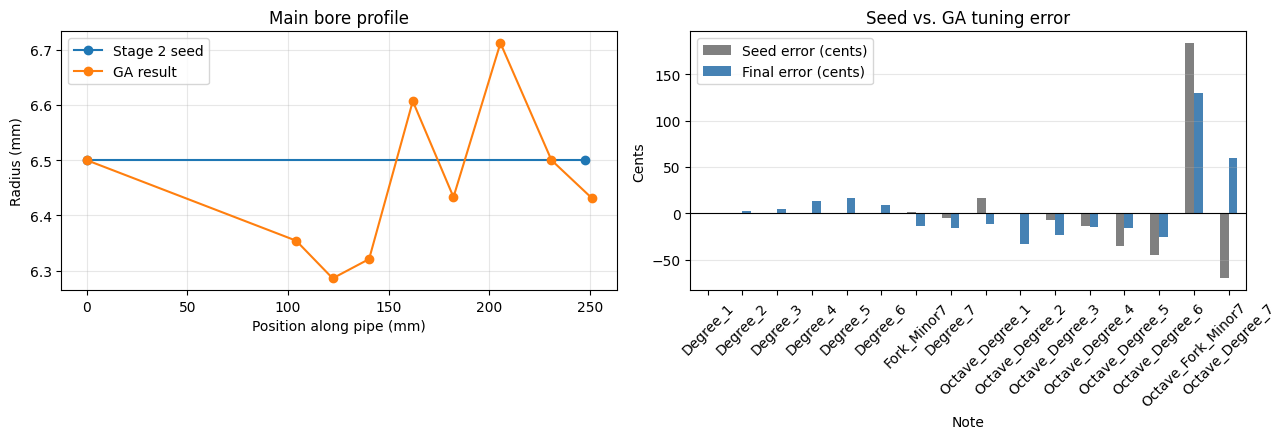

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, bore in (("Stage 2 seed", seed_bore), ("GA result", ga_result.bore)):
    positions_mm = [point[0] * 1000 for point in bore.segments]
    radii_mm = [point[1] * 1000 for point in bore.segments]
    axes[0].plot(positions_mm, radii_mm, marker="o", label=label)
axes[0].set(title="Main bore profile", xlabel="Position along pipe (mm)", ylabel="Radius (mm)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

tuning_table.plot.bar(ax=axes[1], color=["gray", "steelblue"], rot=45)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Seed vs. GA tuning error", ylabel="Cents", xlabel="Note")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Finalize or export the design

Pass the winning geometry/layout into Stage 3 to produce the final design object. When the pipeline receives its own GA result layout, it retains the GA-selected bevel. The dictionary can be serialized as JSON or passed to the project's downstream reporting/export workflow.

In [6]:
final_design = pipeline.run_stage_3_undercut_optimization(
    ga_result.bore,
    ga_result.layout,
)
design_payload = final_design.to_dict()
print(f"Final key: {final_design.key_name}")
print(f"Temperament: {final_design.temperament_name}")
print(f"Selected bevel: {ga_result.dna.bevel_deg:.2f} degrees")
print(f"Bore segment count: {len(final_design.bore.segments)}")
print(f"Tonehole count: {len(final_design.holes.holes)}")

# Optional JSON export (uncomment to write into the repository data directory):
# output_path = Path("data/genetic_whistle_design.json")
# output_path.write_text(json.dumps(design_payload, indent=2), encoding="utf-8")
# print(f"Wrote {output_path}")

Final key: Soprano High D
Temperament: Irish Folk Hybrid (HB-trad / Copeland standard)
Selected bevel: 0.00 degrees
Bore segment count: 9
Tonehole count: 6
